# Sentiment Analysis on IMDB Reviews with Deep Learning

Goal. Classify IMDB movie reviews as positive or negative, compare classical ML with sequence models, and deploy the best model as a small, fast web app.




In [88]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv('/content/IMDB Dataset.csv')

In [5]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
df.shape

(50000, 2)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [9]:
df.isnull().sum()

,0
review,0
sentiment,0


In [10]:
df.duplicated().sum()

np.int64(418)

Remove duplicates and renumbers everything neatly: 0, 1, 2, 3, 4...

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (49582, 2)


In [12]:
print("\nClass distribution:\n", df['sentiment'].value_counts())


Class distribution:
 sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [13]:
print("\nSample review:\n", df['review'][1])


Sample review:
 A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terr

Count how many words are in each review and store it in a new column


In [14]:
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

print(df['word_count'].describe())

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64


plot Number of words in review vs
Number of reviews

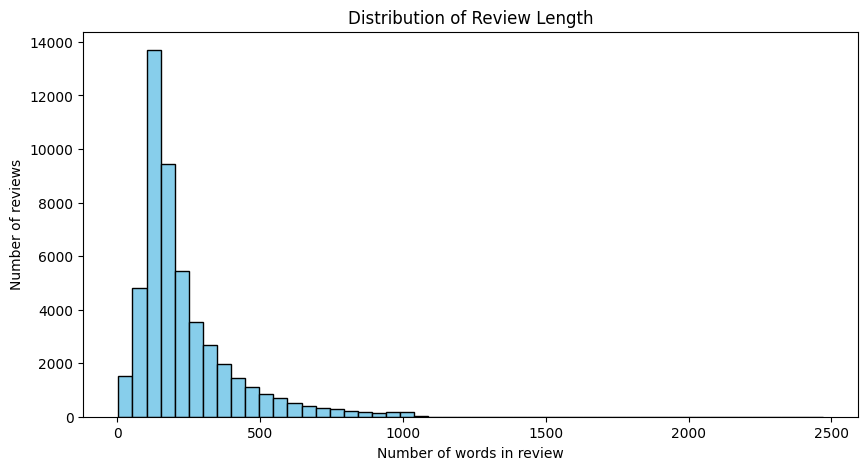

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['word_count'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Review Length')
plt.xlabel('Number of words in review')
plt.ylabel('Number of reviews')
plt.show()

In [16]:
print(df.groupby('sentiment')['word_count'].mean())

sentiment
negative    229.596607
positive    233.090620
Name: word_count, dtype: float64


In [17]:
df.describe()

,word_count
count,49582.000000
mean,231.350167
std,171.542020
min,4.000000
25%,126.000000
50%,173.000000
75%,281.000000
max,2470.000000


The mean (231) is higher than the median (173). This tells us the data is right-skewed.

Imports and word cloud for positive reviews

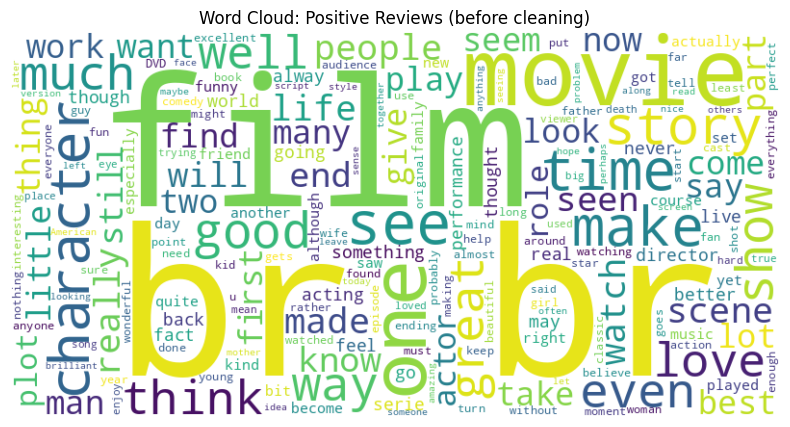

In [18]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Join all positive reviews into one giant string
positive_text = " ".join(df[df['sentiment'] == 'positive']['review'])

# Build the word cloud
wc_pos = WordCloud(width=800, height=400, background_color='white').generate(positive_text)

# Display it
plt.figure(figsize=(10, 5))
plt.imshow(wc_pos, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Positive Reviews (before cleaning)')
plt.show()

word cloud for negative reviews

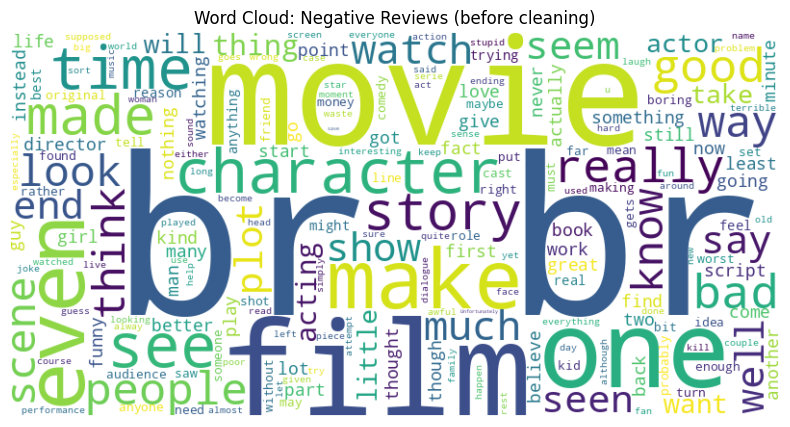

In [19]:
negative_text = " ".join(df[df['sentiment'] == 'negative']['review'])

wc_neg = WordCloud(width=800, height=400, background_color='white').generate(negative_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc_neg, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Negative Reviews (before cleaning)')
plt.show()

Clean the text


- Lowercase everything
- Remove HTML tags (<,<br,/>)
- Fix contractions like didn't → did not
- Remove everything except letters
- Remove stopwords (the, is, and...), but keep negations like not

In [21]:
import re
import nltk
from nltk.corpus import stopwords#downloads its list of boring words.

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

negations = {'not', 'no', 'nor', 'never'}
stop_words = stop_words - negations

print("Number of stopwords we will remove:", len(stop_words))

Number of stopwords we will remove: 195


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [22]:
def clean_text(text):
    text = text.lower()                           # 1. lowercase
    text = re.sub(r'<.*?>', ' ', text)            # 2. remove HTML tags
    text = text.replace("won't", "will not")      # 3. fix contractions
    text = text.replace("can't", "can not")
    text = re.sub(r"n't", " not", text)
    text = re.sub(r'[^a-z\s]', ' ', text)         # 4. keep only letters and spaces
    words = text.split()                          # cut into words
    words = [w for w in words if w not in stop_words]  # 5. remove stopwords
    return " ".join(words)                        # glue back into a sentence

In [23]:
sample = df['review'][1]
print("BEFORE:\n", sample[:300])
print("\nAFTER:\n", clean_text(sample)[:300])

BEFORE:
 A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 

AFTER:
 wonderful little production filming technique unassuming old time bbc fashion gives comforting sometimes discomforting sense realism entire piece actors extremely well chosen michael sheen not got polari voices pat truly see seamless editing guided references williams diary entries not well worth wa


In [24]:
df['clean_review'] = df['review'].apply(clean_text)
df['clean_word_count'] = df['clean_review'].apply(lambda x: len(x.split()))

print("Average words BEFORE cleaning:", round(df['word_count'].mean(), 1))
print("Average words AFTER cleaning: ", round(df['clean_word_count'].mean(), 1))

Average words BEFORE cleaning: 231.4
Average words AFTER cleaning:  121.4


Word clouds again, on the CLEAN text

Positive cloud

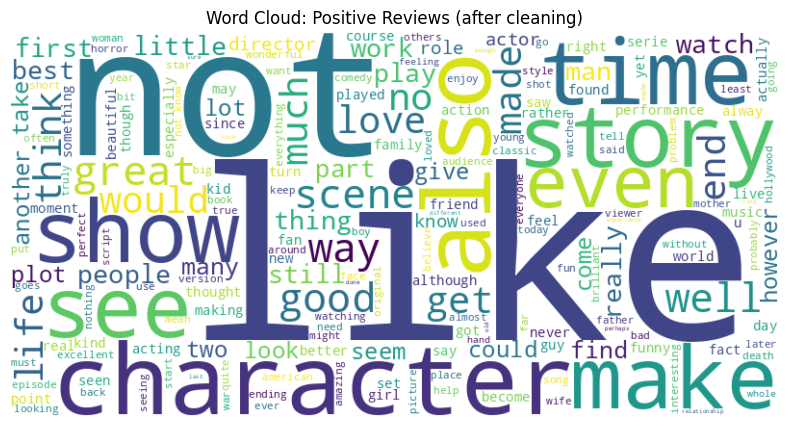

In [25]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

movie_words = {'movie', 'film', 'one', 'movies', 'films'}

positive_clean = " ".join(df[df['sentiment'] == 'positive']['clean_review'])

wc_pos = WordCloud(width=800, height=400, background_color='white',
                   stopwords=movie_words).generate(positive_clean)

plt.figure(figsize=(10, 5))
plt.imshow(wc_pos, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Positive Reviews (after cleaning)')
plt.show()

Negative cloud

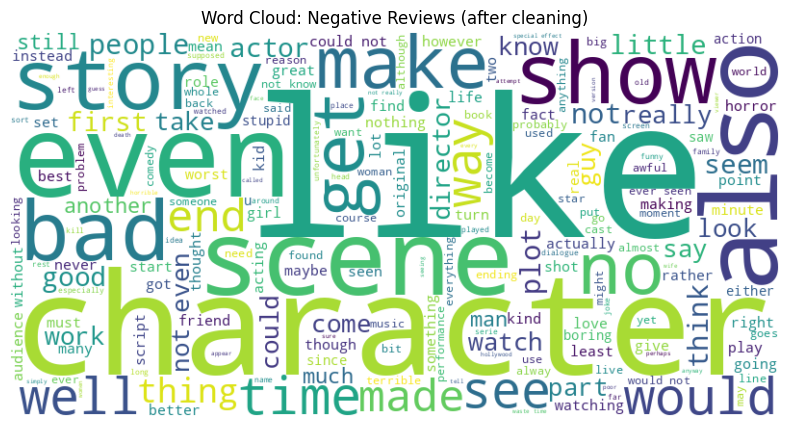

In [26]:
negative_clean = " ".join(df[df['sentiment'] == 'negative']['clean_review'])

wc_neg = WordCloud(width=800, height=400, background_color='white',
                   stopwords=movie_words).generate(negative_clean)

plt.figure(figsize=(10, 5))
plt.imshow(wc_neg, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Negative Reviews (after cleaning)')
plt.show()

Now we use n-grams to count the group of n words that sit together.

In [27]:
from sklearn.feature_extraction.text import CountVectorizer

def top_ngrams(texts, n_words, top_k=15):
    vec = CountVectorizer(ngram_range=(n_words, n_words), max_features=20000)
    counts = vec.fit_transform(texts)

    totals = counts.sum(axis=0).A1          # total times each n-gram appears
    names = vec.get_feature_names_out()     # the n-gram text itself

    top_idx = totals.argsort()[::-1][:top_k]   # positions of the biggest counts
    return [(names[i], int(totals[i])) for i in top_idx]

unigram

In [28]:
pos_texts = df[df['sentiment'] == 'positive']['clean_review']
neg_texts = df[df['sentiment'] == 'negative']['clean_review']

print("TOP 15 WORDS: POSITIVE")
for word, count in top_ngrams(pos_texts, 1):
    print(f"{word:15} {count}")

print("\nTOP 15 WORDS: NEGATIVE")
for word, count in top_ngrams(neg_texts, 1):
    print(f"{word:15} {count}")

TOP 15 WORDS: POSITIVE
not             54719
film            41971
movie           37660
one             27210
like            17651
good            14966
story           12899
great           12889
time            12701
well            12683
see             12225
would           11291
also            10761
really          10707
even            9574

TOP 15 WORDS: NEGATIVE
not             71467
movie           49617
film            37180
one             25995
like            22192
no              15894
would           15174
even            15095
good            14581
bad             14563
really          12217
time            12204
could           11247
see             10598
story           10074


bigram

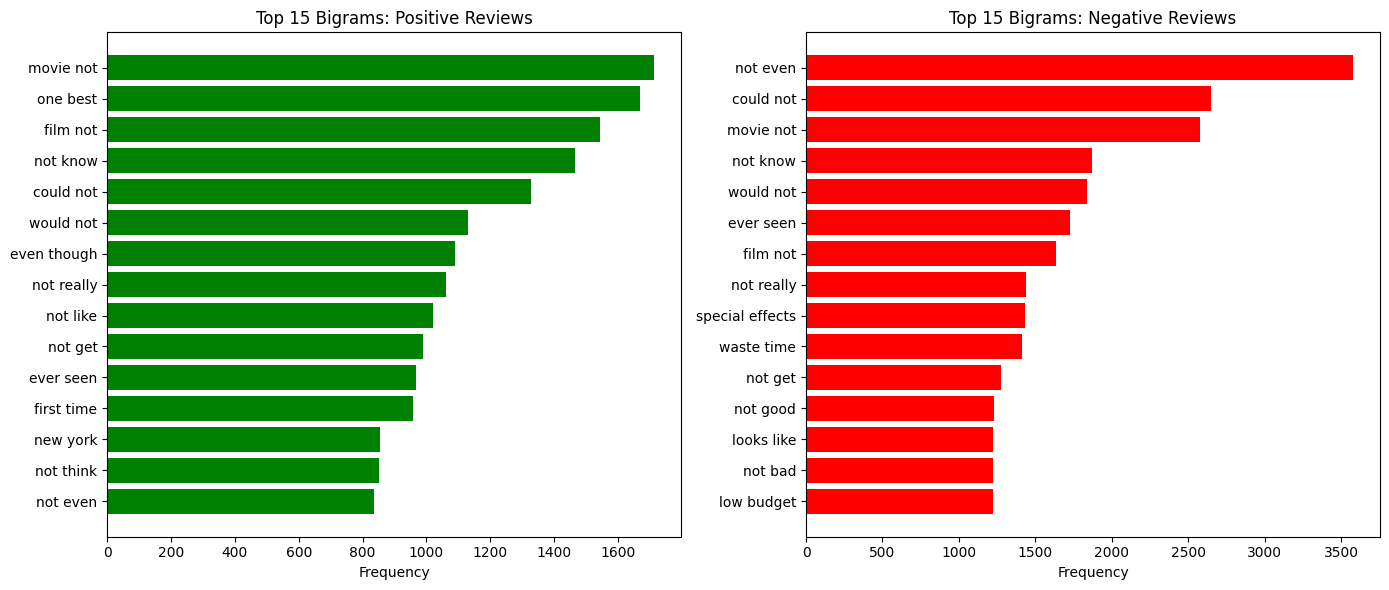

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, texts, title, color in [(axes[0], pos_texts, 'Positive', 'green'),
                                (axes[1], neg_texts, 'Negative', 'red')]:
    data = top_ngrams(texts, 2, top_k=15)
    words = [w for w, c in data]
    counts = [c for w, c in data]
    ax.barh(words[::-1], counts[::-1], color=color)   # flip so #1 is on top
    ax.set_title(f'Top 15 Bigrams: {title} Reviews')
    ax.set_xlabel('Frequency')

plt.tight_layout()
plt.show()

trigram

In [30]:
print("TOP 10 TRIGRAMS: POSITIVE")
for words, count in top_ngrams(pos_texts, 3, top_k=10):
    print(f"{words:30} {count}")

print("\nTOP 10 TRIGRAMS: NEGATIVE")
for words, count in top_ngrams(neg_texts, 3, top_k=10):
    print(f"{words:30} {count}")

TOP 10 TRIGRAMS: POSITIVE
new york city                  195
world war ii                   166
one best movies                143
based true story               135
one best films                 132
movie ever seen                131
first time saw                 115
movies ever seen               112
films ever made                99
even though not                97

TOP 10 TRIGRAMS: NEGATIVE
not waste time                 495
worst movie ever               455
movie ever seen                392
one worst movies               307
worst movies ever              280
movies ever seen               265
not make sense                 243
worst film ever                199
would not recommend            195
movie not even                 191


train/validation/test splits.

In [31]:
# Used to turn text into numbers
df['label'] = df['sentiment'].map({'negative': 0, 'positive': 1})

print(df[['sentiment', 'label']].head())

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1


In [32]:
from sklearn.model_selection import train_test_split

# Step A: set aside 10% as the final TEST set
train_val_df, test_df = train_test_split(
    df, test_size=0.10, random_state=42, stratify=df['label']
)

# Step B: from the remaining 90%, take 1/9 as VALIDATION (that's 10% of the original)
train_df, val_df = train_test_split(
    train_val_df, test_size=1/9, random_state=42, stratify=train_val_df['label']
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (39664, 6)
Validation: (4959, 6)
Test: (4959, 6)


In [33]:
for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(name, "→", part['label'].value_counts(normalize=True).round(3).to_dict())

Train → {1: 0.502, 0: 0.498}
Validation → {1: 0.502, 0: 0.498}
Test → {1: 0.502, 0: 0.498}


Tokenization

Method 1

In [34]:
# Build a vocabulary using plain Python, using TRAIN data only
all_words = " ".join(train_df['clean_review']).split()
unique_words = set(all_words)

print("Total words in training data:", len(all_words))
print("Unique words (vocabulary size):", len(unique_words))

Total words in training data: 4831340
Unique words (vocabulary size): 90643


In [35]:
from collections import Counter

word_counts = Counter(all_words)

rare = sum(1 for w, c in word_counts.items() if c < 5)
print("Words appearing fewer than 5 times:", rare)
print("Percentage of the vocabulary:", round(100 * rare / len(word_counts), 1), "%")

Words appearing fewer than 5 times: 55071
Percentage of the vocabulary: 60.8 %


Methord 2- keras

In [36]:
from tensorflow.keras.preprocessing.text import Tokenizer

VOCAB_SIZE = 20000   # keep only the 20,000 most common words

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(train_df['clean_review'])   # learn the dictionary from TRAIN only

print("First 10 entries in the dictionary:")
print(list(tokenizer.word_index.items())[:10])

First 10 entries in the dictionary:
[('<OOV>', 1), ('not', 2), ('movie', 3), ('film', 4), ('one', 5), ('like', 6), ('good', 7), ('would', 8), ('no', 9), ('time', 10)]


In [37]:
train_seq = tokenizer.texts_to_sequences(train_df['clean_review'])
val_seq   = tokenizer.texts_to_sequences(val_df['clean_review'])
test_seq  = tokenizer.texts_to_sequences(test_df['clean_review'])

# Compare one review: words vs numbers
print("TEXT  :", train_df['clean_review'].iloc[0][:100])
print("NUMBERS:", train_seq[0][:15])

TEXT  : wonderfully put together wish follow documentary follow lives celebrate lives others lost part two r
NUMBERS: [1600, 157, 181, 507, 692, 495, 692, 331, 7500, 331, 279, 305, 76, 33, 56]


In [38]:
import numpy as np

lengths = [len(s) for s in train_seq]
print("Median length:", np.median(lengths))
print("90th percentile:", np.percentile(lengths, 90))
print("95th percentile:", np.percentile(lengths, 95))

Median length: 91.0
90th percentile: 240.0
95th percentile: 315.0


In [39]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 250   # we'll adjust this after seeing the percentiles above

X_train = pad_sequences(train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_val   = pad_sequences(val_seq,   maxlen=MAX_LEN, padding='post', truncating='post')
X_test  = pad_sequences(test_seq,  maxlen=MAX_LEN, padding='post', truncating='post')

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

print("X_train shape:", X_train.shape)
print("First review (padded):", X_train[0][:20])

X_train shape: (39664, 250)
First review (padded): [1600  157  181  507  692  495  692  331 7500  331  279  305   76   33
   56    5   21    4    2   94]


Method 3  subword tokenization, used by BERT.

In [40]:
from transformers import AutoTokenizer

bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")

sentence = "This movie was unwatchable and absolutely mindnumbing"
print("Word-level (Keras):", tokenizer.texts_to_sequences([sentence])[0])
print("Subword (BERT)    :", bert_tok.tokenize(sentence))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Word-level (Keras): [1, 3, 1, 3814, 1, 297, 1]
Subword (BERT)    : ['this', 'movie', 'was', 'un', '##watch', '##able', 'and', 'absolutely', 'mind', '##num', '##bing']


In [48]:
MAX_LEN = 250

X_train = pad_sequences(train_seq, maxlen=MAX_LEN, padding='pre', truncating='post')
X_val   = pad_sequences(val_seq,   maxlen=MAX_LEN, padding='pre', truncating='post')
X_test  = pad_sequences(test_seq,  maxlen=MAX_LEN, padding='pre', truncating='post')

print("X_train shape:", X_train.shape)
print("First 10 numbers of a SHORT review:")
short_idx = np.argmin([len(s) for s in train_seq])
print(X_train[short_idx][:10], "...", X_train[short_idx][-10:])

X_train shape: (39664, 250)
First 10 numbers of a SHORT review:
[0 0 0 0 0 0 0 0 0 0] ... [  0   0   0   0   0   0   0 121  13 808]


Build TF-IDF features

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(train_df['clean_review'])   # learn + convert
X_val_tfidf   = tfidf.transform(val_df['clean_review'])         # convert only
X_test_tfidf  = tfidf.transform(test_df['clean_review'])        # convert only

print("TF-IDF train shape:", X_train_tfidf.shape)

TF-IDF train shape: (39664, 20000)


Train Logistic Regression

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_tfidf, y_train)

val_pred = lr.predict(X_val_tfidf)
print("Baseline validation accuracy:", round(accuracy_score(y_val, val_pred), 4))

Baseline validation accuracy: 0.902


In [47]:
feature_names = np.array(tfidf.get_feature_names_out())
weights = lr.coef_[0]

top_pos = feature_names[np.argsort(weights)[-10:]][::-1]
top_neg = feature_names[np.argsort(weights)[:10]]

print("Most POSITIVE features:", list(top_pos))
print("Most NEGATIVE features:", list(top_neg))

Most POSITIVE features: ['great', 'excellent', 'perfect', 'best', 'wonderful', 'amazing', 'loved', 'favorite', 'brilliant', 'well']
Most NEGATIVE features: ['worst', 'bad', 'awful', 'boring', 'waste', 'poor', 'terrible', 'nothing', 'horrible', 'dull']


In [49]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: []


In [50]:
EMBED_DIM = 128

model = Sequential([
    Input(shape=(MAX_LEN,)),                 # each review = 250 numbers
    Embedding(VOCAB_SIZE, EMBED_DIM),        # word ID -> 128 numbers
    LSTM(64),                                # reads the sequence
    Dropout(0.5),                            # randomly switch off 50% of neurons
    Dense(1, activation='sigmoid')           # final answer: 0 to 1
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,609,473 (9.95 MB)

 Trainable params: 2,609,473 (9.95 MB)

 Non-trainable params: 0 (0.00 B)

In [51]:
early_stop = EarlyStopping(
    monitor='val_loss', patience=2, restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=1, verbose=1
)

In [52]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 222s 352ms/step - accuracy: 0.8487 - loss: 0.3525 - val_accuracy: 0.8836 - val_loss: 0.2819 - learning_rate: 0.0010
Epoch 2/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step - accuracy: 0.9318 - loss: 0.1871
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
620/620 ━━━━━━━━━━━━━━━━━━━━ 203s 328ms/step - accuracy: 0.9270 - loss: 0.1985 - val_accuracy: 0.8740 - val_loss: 0.3084 - learning_rate: 0.0010
Epoch 3/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.9625 - loss: 0.1099
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
620/620 ━━━━━━━━━━━━━━━━━━━━ 209s 337ms/step - accuracy: 0.9618 - loss: 0.1131 - val_accuracy: 0.8857 - val_loss: 0.3232 - learning_rate: 5.0000e-04


In [53]:
histories = {'LSTM': history}      # keep the training record for the curves later
model.save('lstm.keras')           # keep the trained model

In [54]:
from tensorflow.keras.layers import Bidirectional, GRU

def build_and_train(name, rnn_layer):
    m = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(VOCAB_SIZE, EMBED_DIM),
        rnn_layer,
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    m.compile(optimizer=Adam(learning_rate=1e-3),
              loss='binary_crossentropy', metrics=['accuracy'])

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=1, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=1)
    ]

    h = m.fit(X_train, y_train,
              validation_data=(X_val, y_val),
              epochs=6, batch_size=64, callbacks=callbacks)

    m.save(f'{name}.keras')
    return m, h

In [55]:
gru_model, gru_hist = build_and_train('GRU', GRU(64))
histories['GRU'] = gru_hist

Epoch 1/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 288s 451ms/step - accuracy: 0.8384 - loss: 0.3630 - val_accuracy: 0.8855 - val_loss: 0.2870 - learning_rate: 0.0010
Epoch 2/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.9353 - loss: 0.1828
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
620/620 ━━━━━━━━━━━━━━━━━━━━ 231s 373ms/step - accuracy: 0.9312 - loss: 0.1896 - val_accuracy: 0.8861 - val_loss: 0.3027 - learning_rate: 0.0010


In [56]:
bilstm_model, bilstm_hist = build_and_train('BiLSTM', Bidirectional(LSTM(64)))
histories['BiLSTM'] = bilstm_hist

Epoch 1/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 481s 738ms/step - accuracy: 0.8404 - loss: 0.3621 - val_accuracy: 0.8828 - val_loss: 0.2732 - learning_rate: 0.0010
Epoch 2/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.9328 - loss: 0.1910
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
620/620 ━━━━━━━━━━━━━━━━━━━━ 393s 633ms/step - accuracy: 0.9282 - loss: 0.1991 - val_accuracy: 0.8828 - val_loss: 0.2907 - learning_rate: 0.0010


In [58]:
!pip install -q gensim

In [59]:
from gensim.models import Word2Vec

# Word2Vec wants a list of word-lists, one list per review (TRAIN data only)
sentences = [review.split() for review in train_df['clean_review']]

w2v = Word2Vec(
    sentences,
    vector_size=EMBED_DIM,   # 128 numbers per word, same as before
    window=5,
    min_count=5,
    workers=2,
    epochs=10,
    seed=42
)

print("Words learned:", len(w2v.wv))
print("Words similar to 'good':", w2v.wv.most_similar('good', topn=5))
print("Words similar to 'terrible':", w2v.wv.most_similar('terrible', topn=5))

Words learned: 35572
Words similar to 'good': [('decent', 0.7306618094444275), ('great', 0.6806453466415405), ('alright', 0.6296509504318237), ('bad', 0.6255596876144409), ('ok', 0.6189987659454346)]
Words similar to 'terrible': [('horrible', 0.8514649271965027), ('awful', 0.7834203839302063), ('horrendous', 0.7759479880332947), ('horrid', 0.7618946433067322), ('abysmal', 0.7570980191230774)]


In [60]:
embedding_matrix = np.zeros((VOCAB_SIZE, EMBED_DIM))   # start with all zeros
found = 0

for word, idx in tokenizer.word_index.items():
    if idx < VOCAB_SIZE and word in w2v.wv:
        embedding_matrix[idx] = w2v.wv[word]
        found += 1

print("Words found in Word2Vec:", found, "out of", VOCAB_SIZE - 2)

Words found in Word2Vec: 19998 out of 19998


In [61]:
from tensorflow.keras.initializers import Constant

w2v_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBED_DIM,
              embeddings_initializer=Constant(embedding_matrix),
              trainable=False),               # freeze: don't change these vectors
    GRU(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

w2v_model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='binary_crossentropy', metrics=['accuracy'])

w2v_hist = w2v_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=6, batch_size=64,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
               ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=1)]
)

histories['GRU + Word2Vec'] = w2v_hist
w2v_model.save('GRU_w2v.keras')

Epoch 1/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 184s 293ms/step - accuracy: 0.8037 - loss: 0.4321 - val_accuracy: 0.8613 - val_loss: 0.3336 - learning_rate: 0.0010
Epoch 2/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 202s 293ms/step - accuracy: 0.8862 - loss: 0.2851 - val_accuracy: 0.8885 - val_loss: 0.2736 - learning_rate: 0.0010
Epoch 3/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 186s 300ms/step - accuracy: 0.9037 - loss: 0.2460 - val_accuracy: 0.8923 - val_loss: 0.2671 - learning_rate: 0.0010
Epoch 4/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 187s 301ms/step - accuracy: 0.9112 - loss: 0.2277 - val_accuracy: 0.8941 - val_loss: 0.2606 - learning_rate: 0.0010
Epoch 5/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 182s 293ms/step - accuracy: 0.9186 - loss: 0.2121 - val_accuracy: 0.8968 - val_loss: 0.2600 - learning_rate: 0.0010
Epoch 6/6
620/620 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.9243 - loss: 0.1949
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
620/620 ━━━━━━━━━━━━━━━━━━━━ 206s 300ms/step - accuracy: 0.924

In [62]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

def evaluate(name, probs, y_true):
    preds = (probs >= 0.5).astype(int)      # probability -> 0 or 1
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds),
        'Recall':    recall_score(y_true, preds),
        'F1':        f1_score(y_true, preds),
        'ROC-AUC':   roc_auc_score(y_true, probs)
    }

In [63]:
test_probs = {}

# Classical model: TF-IDF + Logistic Regression
test_probs['TF-IDF + LogReg'] = lr.predict_proba(X_test_tfidf)[:, 1]

# Neural models (verbose=0 hides the progress bars)
test_probs['LSTM']           = model.predict(X_test, batch_size=128, verbose=0).ravel()
test_probs['GRU']            = gru_model.predict(X_test, batch_size=128, verbose=0).ravel()
test_probs['BiLSTM']         = bilstm_model.predict(X_test, batch_size=128, verbose=0).ravel()
test_probs['GRU + Word2Vec'] = w2v_model.predict(X_test, batch_size=128, verbose=0).ravel()

print("Done:", list(test_probs.keys()))

Done: ['TF-IDF + LogReg', 'LSTM', 'GRU', 'BiLSTM', 'GRU + Word2Vec']


In [64]:
results = pd.DataFrame([evaluate(n, p, y_test) for n, p in test_probs.items()])
results = results.set_index('Model').round(4)
display(results.sort_values('F1', ascending=False))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
GRU + Word2Vec,0.9006,0.8856,0.9209,0.9029,0.9609
TF-IDF + LogReg,0.8994,0.8908,0.9112,0.9009,0.9631
GRU,0.8820,0.8560,0.9196,0.8867,0.9513
BiLSTM,0.8851,0.8905,0.8791,0.8848,0.9540
LSTM,0.8786,0.8543,0.9140,0.8832,0.9514


Confusion matrices for all 5 models

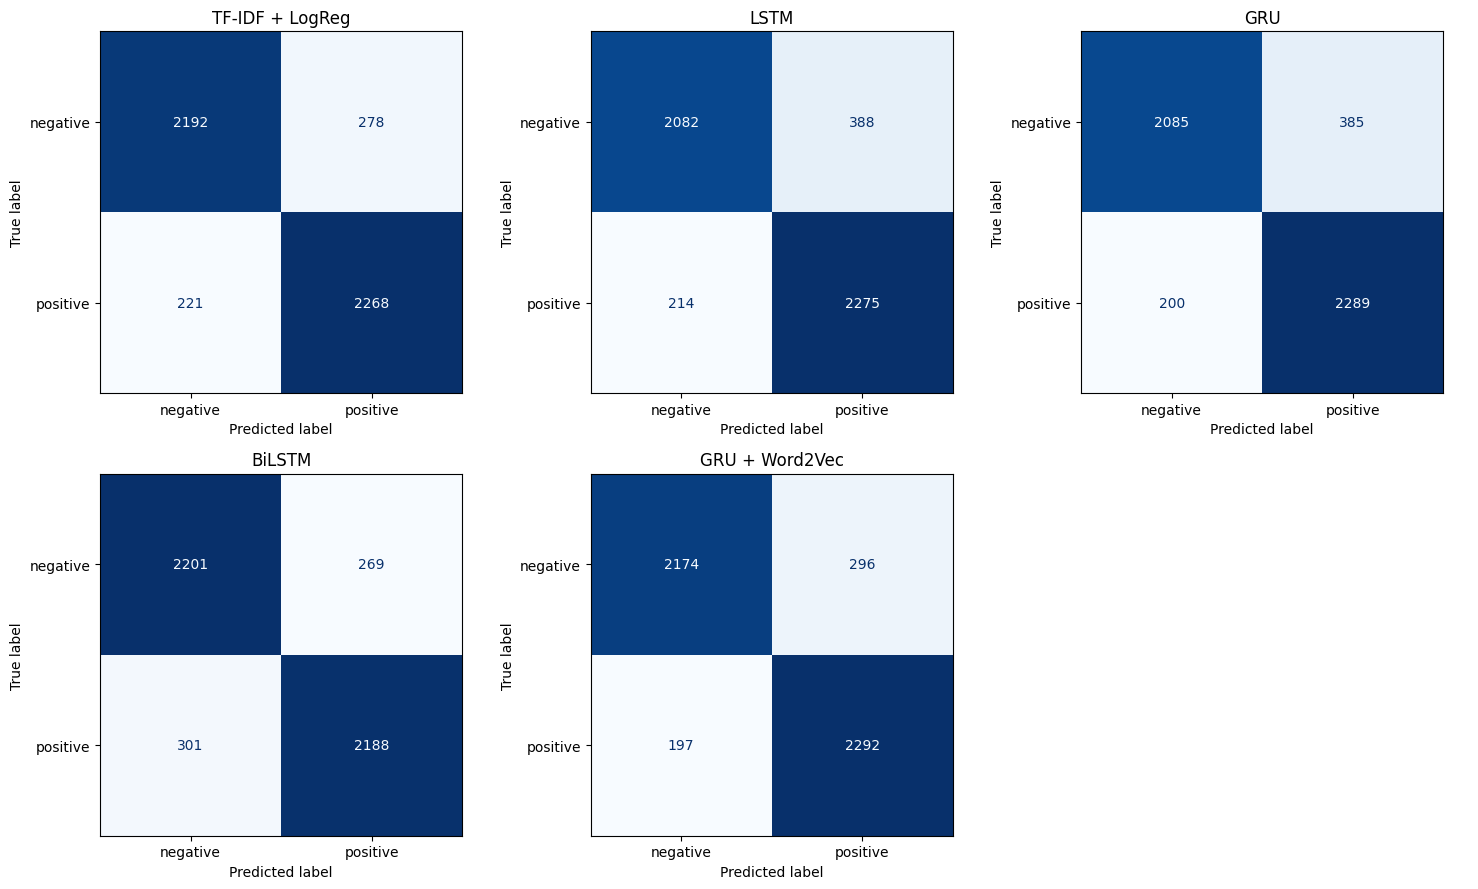

In [65]:
  import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (name, probs) in zip(axes, test_probs.items()):
    preds = (probs >= 0.5).astype(int)
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

axes[-1].axis('off')      # the 6th box is empty, so hide it
plt.tight_layout()
plt.show()

In [66]:
from sklearn.metrics import classification_report

best_preds = (test_probs['GRU + Word2Vec'] >= 0.5).astype(int)
print(classification_report(y_test, best_preds,
                            target_names=['negative', 'positive'], digits=4))

              precision    recall  f1-score   support

    negative     0.9169    0.8802    0.8982      2470
    positive     0.8856    0.9209    0.9029      2489

    accuracy                         0.9006      4959
   macro avg     0.9013    0.9005    0.9005      4959
weighted avg     0.9012    0.9006    0.9005      4959



ROC curves

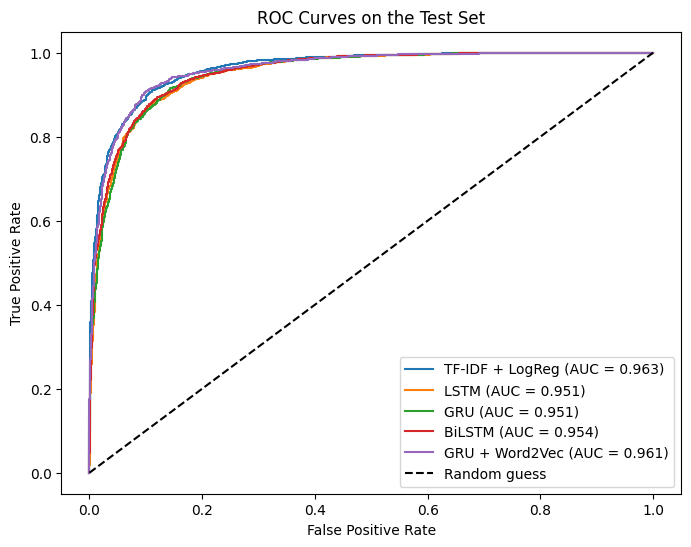

In [67]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))
for name, probs in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves on the Test Set')
plt.legend(loc='lower right')
plt.show()

Training curves

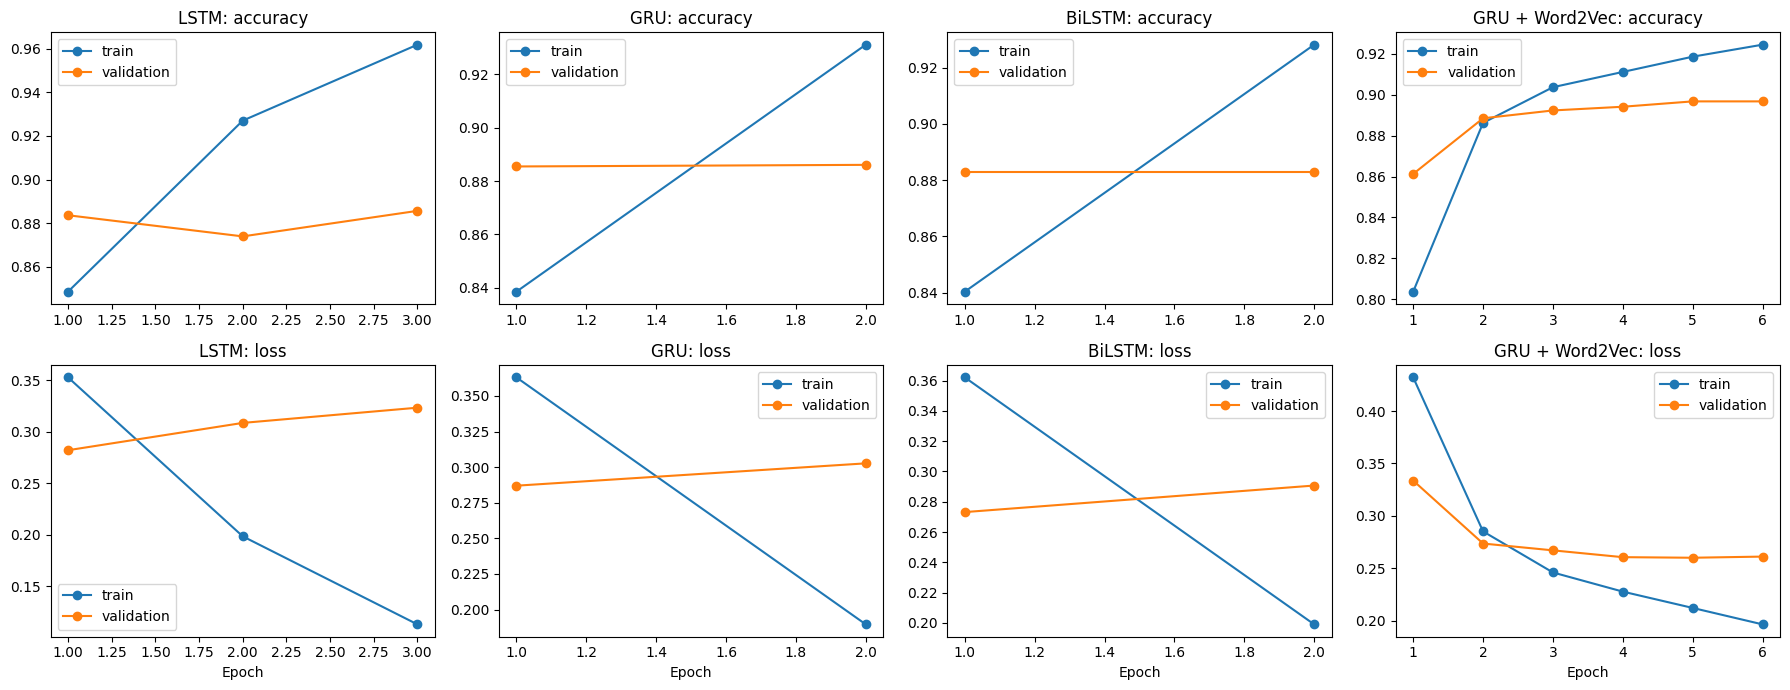

In [68]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for col, (name, h) in enumerate(histories.items()):
    ep = range(1, len(h.history['loss']) + 1)

    axes[0, col].plot(ep, h.history['accuracy'], 'o-', label='train')
    axes[0, col].plot(ep, h.history['val_accuracy'], 'o-', label='validation')
    axes[0, col].set_title(f'{name}: accuracy')
    axes[0, col].legend()

    axes[1, col].plot(ep, h.history['loss'], 'o-', label='train')
    axes[1, col].plot(ep, h.history['val_loss'], 'o-', label='validation')
    axes[1, col].set_title(f'{name}: loss')
    axes[1, col].set_xlabel('Epoch')
    axes[1, col].legend()

plt.tight_layout()
plt.show()

Collect the mistakes

In [69]:
err_df = test_df.copy()
err_df['prob'] = test_probs['GRU + Word2Vec']                # model confidence
err_df['pred'] = (err_df['prob'] >= 0.5).astype(int)         # model decision
err_df['correct'] = err_df['pred'] == err_df['label']        # True / False

errors = err_df[~err_df['correct']].copy()

print("Total mistakes:", len(errors), "out of", len(err_df))
print("Negative reviews called positive (false positives):", (errors['label'] == 0).sum())
print("Positive reviews called negative (false negatives):", (errors['label'] == 1).sum())

Total mistakes: 493 out of 4959
Negative reviews called positive (false positives): 296
Positive reviews called negative (false negatives): 197


The model’s most confident mistakes

In [70]:
import numpy as np

# Confidence in the WRONG answer: how sure was the model about what it said?
errors['confidence'] = np.where(errors['pred'] == 1, errors['prob'], 1 - errors['prob'])
worst = errors.sort_values('confidence', ascending=False).head(5)

for _, r in worst.iterrows():
    said = 'positive' if r['pred'] == 1 else 'negative'
    print(f"TRUE: {r['sentiment']} | model said {said} ({r['confidence']:.1%} sure)")
    print(r['review'][:600], "...\n")

TRUE: positive | model said negative (99.5% sure)
It's hard to imagine a director capable of such godawful crap as 'Notting Hill' pulling off something as sensitive and as attractive as this, but well, here's the evidence and it's quite compelling. Several have alluded to TV drama, and yes, this does have a seventies Play for Today feel at times, but is always a cut above, mainly I think owing to some quite superlative acting from Anne Reid and to a fine script which shadow-boxes with cliché without ever getting one on the nose, except maybe right at the end. (I didn't like either the tracking shot of indifferent goodbyes through the hallway, ...

TRUE: negative | model said positive (99.4% sure)
this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she h

In [71]:
err_df['too_long'] = err_df['clean_word_count'] > MAX_LEN

print(err_df.groupby('too_long')['correct'].agg(['mean', 'count']).round(4))
print("\nAvg length, correct vs wrong:")
print(err_df.groupby('correct')['clean_word_count'].mean().round(1))

            mean  count
too_long               
False     0.9037   4507
True      0.8695    452

Avg length, correct vs wrong:
correct
False    133.1
True     118.5
Name: clean_word_count, dtype: float64


In [72]:
for _, r in worst.iloc[[2, 4]].iterrows():
    print(f"TRUE: {r['sentiment']} | words: {r['clean_word_count']}")
    print("...", r['review'][-500:], "\n")

TRUE: negative | words: 68
... ormance, most of the others were also very engaging. In particular, the interplay between the policemen was natural and well-balanced, and worked very well.<br /><br />It is only about 45 minutes long, so the plot is not complex. More key is the style of the whole thing. It is very slick and vibrant, and the backdrops are atmospheric, especially from the fact that all the colours are extremely rich. The gangland is identifiable to foreign audiences, but still manages to be distinctly Australian. 

TRUE: negative | words: 245
... her first lead role, proves she can be charming and funny. Dermot Mulrony has great chemistry with Debra Messing, but most of his dialogue was too corny and unrealistic. He is able to make best of what he is given, and be able to salvage the character. <br /><br />By the use of many clever puns (often sexual), the film is actually funny. Although primarily a chick-flick the film has components everyone can enjoy. The feel good sto

In [73]:
err_df['tfidf_correct'] = ((test_probs['TF-IDF + LogReg'] >= 0.5).astype(int)
                           == err_df['label'].values)

print(err_df.groupby('too_long')[['correct', 'tfidf_correct']].mean().round(4))

          correct  tfidf_correct
too_long                        
False      0.9037         0.8979
True       0.8695         0.9137


In [74]:
print("Mistakes where the model was more than 90% sure:",
      (errors['confidence'] > 0.9).sum(), "of", len(errors))

sample = errors.sample(10, random_state=1)
for _, r in sample.iterrows():
    said = 'positive' if r['pred'] == 1 else 'negative'
    print(f"\nTRUE: {r['sentiment']} | model said {said} ({r['confidence']:.0%} sure)")
    print(r['review'][:400], "...")

Mistakes where the model was more than 90% sure: 156 of 493

TRUE: positive | model said negative (98% sure)
This is not a GREAT movie as tho the cast (especially the kids) admirably help to carry along this very sad yet contrived plot it is filled with cliché upon cliché. Poor family in 50's mid America, dying mother, alcoholic father, 10 children (1 of whom has epilepsy) and an awful decision to be made. Its very easy to watch and some of the kids performances are moving without being sickly or naff. A ...

TRUE: negative | model said positive (93% sure)
I was in 6th grade and this movie aired on PBS during a series called 'Wonderworks.' I distinctly remember sitting on a couch watching the movie with tears running down my face at the end. In the film Jesse, the main character, forms an unusual friendship with a girl named Leslie. Due to a very simple, but careless mistake one of the pair dies. At the time, I found the story very powerful, because ...

TRUE: positive | model said neg

In [75]:
import os, pickle, json

# 1. The tokenizer (the word -> number dictionary)
with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

# 2. Settings the app needs to prepare text exactly like training
with open('config.json', 'w') as f:
    json.dump({'MAX_LEN': MAX_LEN, 'VOCAB_SIZE': VOCAB_SIZE}, f)

# 3. The stopword list we used (so the app doesn't need to download it)
with open('stop_words.json', 'w') as f:
    json.dump(sorted(stop_words), f)

print([x for x in os.listdir('.') if x.endswith(('.keras', '.pkl', '.json'))])

['stop_words.json', 'lstm.keras', 'tokenizer.pkl', 'GRU.keras', 'GRU_w2v.keras', 'config.json', 'BiLSTM.keras']


In [76]:
import time, os, pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 100 cleaned test reviews to time (one at a time, like a real app)
sample_texts = test_df['clean_review'].iloc[:100].tolist()

def nn_predictor(m):
    def predict_one(text):
        seq = tokenizer.texts_to_sequences([text])
        seq = pad_sequences(seq, maxlen=MAX_LEN, padding='pre', truncating='post')
        return m(seq, training=False)
    return predict_one

def tfidf_predict(text):
    return lr.predict_proba(tfidf.transform([text]))

def avg_ms(fn, texts):
    for t in texts[:5]:                 # warm-up runs (the first call is always slow)
        fn(t)
    start = time.perf_counter()
    for t in texts:
        fn(t)
    return (time.perf_counter() - start) / len(texts) * 1000

Measure all 5 models

In [77]:
def weights_mb(m, name):
    path = f'tmp_{name}.weights.h5'
    m.save_weights(path)                      # weights only, no optimizer notes
    size = os.path.getsize(path) / (1024 * 1024)
    os.remove(path)                           # delete the temporary file
    return size

# Save the classical model too (we'll need it for comparison, maybe the app)
with open('tfidf_logreg.pkl', 'wb') as f:
    pickle.dump({'tfidf': tfidf, 'lr': lr}, f)

nn_models = {'LSTM': model, 'GRU': gru_model,
             'BiLSTM': bilstm_model, 'GRU + Word2Vec': w2v_model}

rows = []
for i, (name, m) in enumerate(nn_models.items()):
    rows.append({'Model': name,
                 'Size (MB)': weights_mb(m, f'm{i}'),
                 'ms per review': avg_ms(nn_predictor(m), sample_texts)})

rows.append({'Model': 'TF-IDF + LogReg',
             'Size (MB)': os.path.getsize('tfidf_logreg.pkl') / (1024 * 1024),
             'ms per review': avg_ms(tfidf_predict, sample_texts)})

speed_df = pd.DataFrame(rows).set_index('Model').round(2)
display(results[['Accuracy', 'F1']].join(speed_df))

,Accuracy,F1,Size (MB),ms per review
Model,,,,
TF-IDF + LogReg,0.8994,0.9009,0.89,1.62
LSTM,0.8786,0.8832,29.89,842.97
GRU,0.8820,0.8867,29.75,1164.13
BiLSTM,0.8851,0.8848,30.46,1650.99
GRU + Word2Vec,0.9006,0.9029,10.22,1151.22


In [78]:
import tensorflow as tf

def nn_predictor(m):
    # tf.function compiles the model into a fast graph (like training does)
    @tf.function(input_signature=[tf.TensorSpec(shape=(1, MAX_LEN), dtype=tf.int32)])
    def run(x):
        return m(x, training=False)

    def predict_one(text):
        seq = tokenizer.texts_to_sequences([text])
        seq = pad_sequences(seq, maxlen=MAX_LEN, padding='pre', truncating='post')
        return run(tf.constant(seq, dtype=tf.int32))
    return predict_one

def size_mb(m):
    return m.count_params() * 4 / (1024 * 1024)    # 4 bytes per float32 number

rows = []
for name, m in nn_models.items():
    rows.append({'Model': name,
                 'Size (MB)': size_mb(m),
                 'ms per review': avg_ms(nn_predictor(m), sample_texts)})

rows.append({'Model': 'TF-IDF + LogReg',
             'Size (MB)': os.path.getsize('tfidf_logreg.pkl') / (1024 * 1024),
             'ms per review': avg_ms(tfidf_predict, sample_texts)})

speed_df = pd.DataFrame(rows).set_index('Model').round(2)
display(results[['Accuracy', 'F1']].join(speed_df))

,Accuracy,F1,Size (MB),ms per review
Model,,,,
TF-IDF + LogReg,0.8994,0.9009,0.89,0.98
LSTM,0.8786,0.8832,9.95,20.48
GRU,0.8820,0.8867,9.91,16.03
BiLSTM,0.8851,0.8848,10.14,19.46
GRU + Word2Vec,0.9006,0.9029,9.91,15.79


In [79]:
emb_layer = [l for l in w2v_model.layers if isinstance(l, Embedding)][0]
original = emb_layer.get_weights()[0]              # shape (20000, 128)

# float16: store each number in 2 bytes, then expand back to compare
w_fp16 = original.astype(np.float16).astype(np.float32)

# int8: one scale per word, so each word gets its own "ruler"
scales = np.abs(original).max(axis=1, keepdims=True) / 127.0
scales[scales == 0] = 1.0                          # all-zero rows (padding, OOV) would divide by 0
q = np.round(original / scales).astype(np.int8)    # whole numbers from -127 to 127
w_int8 = q.astype(np.float32) * scales             # expand back to compare

print("Word 'movie' (ID 3), first 5 numbers")
print("original:", original[3][:5].round(4))
print("float16 :", w_fp16[3][:5].round(4))
print("int8    :", w_int8[3][:5].round(4))

Word 'movie' (ID 3), first 5 numbers
original: [-0.6184 -0.6069  1.2502  1.8075  0.3893]
float16 : [-0.6182 -0.6069  1.25    1.8076  0.3894]
int8    : [-0.6096 -0.6096  1.2586  1.8092  0.3933]


In [80]:
def test_with_embedding(name, table):
    emb_layer.set_weights([table])
    probs = w2v_model.predict(X_test, batch_size=128, verbose=0).ravel()
    return evaluate(name, probs, y_test)

other = w2v_model.count_params() - original.size        # the non-embedding numbers (GRU + Dense)
mb = lambda b: b / (1024 * 1024)

rows = [
    {**test_with_embedding('float32 (original)', original),
     'Size (MB)': mb(w2v_model.count_params() * 4)},
    {**test_with_embedding('float16 embeddings', w_fp16),
     'Size (MB)': mb(original.size * 2 + other * 4)},
    {**test_with_embedding('int8 embeddings', w_int8),
     'Size (MB)': mb(original.size * 1 + scales.size * 4 + other * 4)},
]

emb_layer.set_weights([original])                       # always put the original back!

quant_df = pd.DataFrame(rows).set_index('Model').round(4)
display(quant_df)

,Accuracy,Precision,Recall,F1,ROC-AUC,Size (MB)
Model,,,,,,
float32 (original),0.9006,0.8856,0.9209,0.9029,0.9609,9.9080
float16 embeddings,0.9006,0.8856,0.9209,0.9029,0.9609,5.0252
int8 embeddings,0.9006,0.8856,0.9209,0.9029,0.9609,2.6600


In [81]:
# probabilities with the ORIGINAL embeddings
emb_layer.set_weights([original])
p_orig = w2v_model.predict(X_test, batch_size=128, verbose=0).ravel()

# probabilities with the int8 embeddings
emb_layer.set_weights([w_int8])
p_int8 = w2v_model.predict(X_test, batch_size=128, verbose=0).ravel()

emb_layer.set_weights([original])        # restore the original

diff = np.abs(p_orig - p_int8)
print("Biggest change in any review's probability:", diff.max().round(5))
print("Average change:", diff.mean().round(6))

flips = ((p_orig >= 0.5) != (p_int8 >= 0.5)).sum()
print("Reviews whose predicted class flipped:", flips, "of", len(p_orig))

Biggest change in any review's probability: 0.0127
Average change: 0.000567
Reviews whose predicted class flipped: 2 of 4959


In [82]:
import tensorflow as tf

export_dir = 'gru_w2v_savedmodel'
w2v_model.export(export_dir,
                 input_signature=[tf.TensorSpec(shape=(1, MAX_LEN), dtype=tf.int32)])

Saved artifact at 'gru_w2v_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 250), dtype=tf.int32, name=None)
Output Type:
  TensorSpec(shape=(1, 1), dtype=tf.float32, name=None)
Captures:
  134243247656400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134243247657936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134243247656976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134243247657360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134243247658320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134243247658512: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [83]:
def to_tflite(quantize):
    conv = tf.lite.TFLiteConverter.from_saved_model(export_dir)
    # Allow fallback to full TensorFlow ops, in case a GRU piece isn't supported natively
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS,
                                      tf.lite.OpsSet.SELECT_TF_OPS]
    if quantize:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]   # compress weights to int8
    return conv.convert()

tflite_fp32 = to_tflite(False)
tflite_int8 = to_tflite(True)

print("TFLite float32 size (MB):", round(len(tflite_fp32) / (1024 * 1024), 2))
print("TFLite int8 size (MB)   :", round(len(tflite_int8) / (1024 * 1024), 2))

TFLite float32 size (MB): 9.92
TFLite int8 size (MB)   : 2.49


In [84]:
def make_runner(blob):
    interp = tf.lite.Interpreter(model_content=blob)
    interp.allocate_tensors()
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    def run(x):                                    # x has shape (1, MAX_LEN)
        interp.set_tensor(inp['index'], x.astype(inp['dtype']))
        interp.invoke()
        return interp.get_tensor(out['index'])
    return run

runners = {'TFLite float32': make_runner(tflite_fp32),
           'TFLite int8':    make_runner(tflite_int8)}
sizes = {'TFLite float32': len(tflite_fp32), 'TFLite int8': len(tflite_int8)}

rows = []
for name, run in runners.items():
    # speed: full journey from text to probability, like the real app
    def predict_one(text, run=run):
        seq = tokenizer.texts_to_sequences([text])
        seq = pad_sequences(seq, maxlen=MAX_LEN, padding='pre', truncating='post')
        return run(seq)
    ms = avg_ms(predict_one, sample_texts)

    # accuracy: whole test set, one review at a time
    probs = np.array([run(X_test[i:i+1])[0][0] for i in range(len(X_test))])
    row = evaluate(name, probs, y_test)
    row['Size (MB)'] = sizes[name] / (1024 * 1024)
    row['ms per review'] = ms
    rows.append(row)

tflite_df = pd.DataFrame(rows).set_index('Model').round(4)
display(tflite_df)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Accuracy,Precision,Recall,F1,ROC-AUC,Size (MB),ms per review
Model,,,,,,,
TFLite float32,0.9006,0.8856,0.9209,0.9029,0.9609,9.9185,1.9670
TFLite int8,0.9006,0.8862,0.9200,0.9028,0.9610,2.4935,1.4206


In [85]:
with open('sentiment_gru_w2v_int8.tflite', 'wb') as f:
    f.write(tflite_int8)

with open('sentiment_gru_w2v_fp32.tflite', 'wb') as f:
    f.write(tflite_fp32)

print([x for x in os.listdir('.') if x.endswith(('.tflite', '.pkl', '.json', '.keras'))])

['stop_words.json', 'lstm.keras', 'tfidf_logreg.pkl', 'tokenizer.pkl', 'GRU.keras', 'GRU_w2v.keras', 'sentiment_gru_w2v_fp32.tflite', 'sentiment_gru_w2v_int8.tflite', 'config.json', 'BiLSTM.keras']


In [86]:
!pip install -q gradio

In [87]:
import gradio as gr

run_int8 = runners['TFLite int8']      # the small, fast model

def predict_sentiment(review):
    if not review or not review.strip():
        raise gr.Error("Please type a review first.")
    cleaned = clean_text(review)                               # same cleaning as training
    seq = tokenizer.texts_to_sequences([cleaned])              # words -> numbers
    seq = pad_sequences(seq, maxlen=MAX_LEN, padding='pre', truncating='post')
    p_pos = float(run_int8(seq)[0][0])                         # probability of positive
    return {"positive": p_pos, "negative": 1 - p_pos}

demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(lines=6, label="Movie review",
                      placeholder="Type or paste a movie review here..."),
    outputs=gr.Label(num_top_classes=2, label="Prediction (confidence)"),
    examples=[
        ["An absolute masterpiece. The acting was superb and I loved every minute."],
        ["Boring, predictable and way too long. What a waste of time."],
        ["I did not enjoy this film at all."],
        ["Oh great, another two hours of my life I will never get back. Wonderful."],
    ],
    title="SentimentForge: Movie Review Sentiment",
    description=("GRU + Word2Vec model (int8 TFLite, 2.5 MB). Scores are the model's own "
                 "confidence and can be too high on tricky reviews such as sarcasm."),
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b41d490235827ea07d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


#Insights and Recommendations
 #Key insights
- Strong accuracy with a simple model. GRU + Word2Vec reaches 90.06% accuracy and 0.9029 F1 on unseen data. TF-IDF + Logistic Regression is only 0.12 points behind, so a simple model is a hard baseline to beat on this task.
- Good embeddings beat more complex architectures. Pretraining Word2Vec vectors on the training reviews and freezing them helped more than switching from LSTM to GRU or BiLSTM.
- Deployment cost can be cut sharply. int8 quantisation reduces the model from 9.9 MB to 2.5 MB and inference time to about 1.4 ms per review, with no loss in accuracy.
- Failures are predictable. Most errors come from long reviews that are truncated, mixed opinions, sarcasm, and reviews that mostly describe the plot.
#Recommendations for real-world use
- Customer feedback analysis. Run the int8 model on incoming reviews, tickets or survey comments to give each a positive/negative score, then track the share of negative feedback by product, feature or week. At about 1.4 ms per review, hundreds of thousands of reviews can be scored on a single CPU.
- Review monitoring and alerts. Raise an alert when the negative share rises suddenly (for example after a release). Use the confidence score so that only high-confidence negatives trigger an alert.
- Human review for uncertain cases. Send predictions with probabilities between about 0.4 and 0.6, and very long or mixed reviews, to a person. This is where the model is least reliable.
- Choose the model to fit the need. Use TF-IDF + LogReg when the smallest footprint and easy explanation matter most, and the quantised GRU + Word2Vec model when the best accuracy matters.
- Keep the model current. Retrain regularly on fresh labelled reviews from your own domain, because vocabulary and slang change over time, and the model was trained on movie reviews only.
#Limitations and next steps
Sarcasm and mixed sentiment ("great acting, terrible film") are often misclassified, sometimes with high confidence.
Binary labels only. The model has no neutral class, so neutral reviews are forced into positive or negative.
Domain shift. The model is trained on movie reviews. Accuracy on product, hotel or social-media text will likely be lower without retraining.
Truncation. Only the first 250 words are used, which hurts long reviews.
Future work. Fine-tune a pretrained transformer (for example DistilBERT), try GloVe or FastText embeddings, add a neutral class, and compare several MAX_LEN settings.